### Cell 1: Nạp dữ liệu, đồng nhất chia tập 60/20/20 và dựng Popularity Baseline chỉ trên Train
- Sử dụng đúng phép chia `60% Train / 20% Validation / 20% Test` (`random_state=42, shuffle=True`) khớp với `collaborative_filtering.ipynb`.
- Mọi thống kê độ phổ biến (`rating_count`, `rating_mean`, `global_mean`) chỉ tính trên `train_df` để loại bỏ rò rỉ dữ liệu từ tập Test.

In [1]:
import heapq
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import linear_kernel
from surprise import Dataset, Reader, SVD, accuracy

DATA_DIR = os.path.join("..", "..", "data", "processed")
MODEL_DIR = os.path.join("..", "saved_models")
IMG_DIR = os.path.join("..", "..", "docs", "images")
os.makedirs(IMG_DIR, exist_ok=True)

ratings_df = pd.read_csv(os.path.join(DATA_DIR, "ratings_cleaned.csv"))
books_df = pd.read_csv(os.path.join(DATA_DIR, "books_cleaned.csv"), low_memory=False)

ratings_df["User-ID"] = ratings_df["User-ID"].astype(int)
ratings_df["ISBN"] = ratings_df["ISBN"].astype(str)
ratings_df["Book-Rating"] = ratings_df["Book-Rating"].astype(float)

# Chia tập 60/20/20 đồng nhất với collaborative_filtering.ipynb
train_val_df, test_df = train_test_split(ratings_df, test_size=0.20, random_state=42, shuffle=True)
train_df, val_df = train_test_split(train_val_df, test_size=0.25, random_state=42, shuffle=True)

svd_model = joblib.load(os.path.join(MODEL_DIR, "collaborative_model.pkl"))
cb_data = joblib.load(os.path.join(MODEL_DIR, "content_based_model.pkl"))

# Popularity Baseline tính hoàn toàn trên tập Train (không rò rỉ dữ liệu Test)
train_book_stats = train_df.groupby("ISBN")["Book-Rating"].agg(["count", "mean"]).reset_index()
pop_eligible_df = train_book_stats[train_book_stats["count"] >= 10].sort_values(
    ["mean", "count"], ascending=False
)
pop_score_map = dict(zip(pop_eligible_df["ISBN"], pop_eligible_df["mean"]))
global_train_mean = float(train_df["Book-Rating"].mean())

print(f"Train: {len(train_df):,} | Val: {len(val_df):,} | Test: {len(test_df):,}")
print(f"Sách đủ ngưỡng Popularity (>=10 lượt trên Train): {len(pop_eligible_df):,} | Global Train Mean: {global_train_mean:.4f}")

Train: 230,304 | Val: 76,769 | Test: 76,769
Sách đủ ngưỡng Popularity (>=10 lượt trên Train): 2,897 | Global Train Mean: 7.6254


### Cell 2: Đánh giá sai số dự đoán điểm (RMSE & MAE) trên tập Test độc lập (20%)
- So sánh trực tiếp **Collaborative Filtering (FunkSVD)** và **Popularity-Based (Train-only Baseline)** trên toàn bộ tập Test, đồng thời tách nhóm **Warm Test Users** (có trong `trainset` của SVD) với **Cold Test Users** (không có trong `trainset`).

In [2]:
testset = list(test_df[["User-ID", "ISBN", "Book-Rating"]].itertuples(index=False, name=None))
svd_preds = svd_model.test(testset)
svd_rmse = accuracy.rmse(svd_preds, verbose=False)
svd_mae = accuracy.mae(svd_preds, verbose=False)

y_true = test_df["Book-Rating"].values
y_pred_pop = test_df["ISBN"].map(pop_score_map).fillna(global_train_mean).values
pop_rmse = float(np.sqrt(np.mean((y_true - y_pred_pop) ** 2)))
pop_mae = float(np.mean(np.abs(y_true - y_pred_pop)))

# Phân tách Warm vs Cold Users trên tập Test dựa vào svd_model.trainset
train_user_set = set(train_df["User-ID"].unique())
is_warm_user = test_df["User-ID"].isin(train_user_set).values
svd_est_arr = np.array([p.est for p in svd_preds])

for label, mask in [("Toàn tập Test (100%)", np.ones(len(test_df), dtype=bool)), ("Warm Users (có trong Train)", is_warm_user), ("Cold Users (chưa có trong Train)", ~is_warm_user)]:
    s_rmse = np.sqrt(np.mean((y_true[mask] - svd_est_arr[mask]) ** 2))
    s_mae = np.mean(np.abs(y_true[mask] - svd_est_arr[mask]))
    p_rmse = np.sqrt(np.mean((y_true[mask] - y_pred_pop[mask]) ** 2))
    p_mae = np.mean(np.abs(y_true[mask] - y_pred_pop[mask]))
    print(f"{label:34s} (n={mask.sum():6,}) | SVD RMSE={s_rmse:.4f}, MAE={s_mae:.4f} | Pop RMSE={p_rmse:.4f}, MAE={p_mae:.4f}")

rmse_gain = (pop_rmse - svd_rmse) / pop_rmse * 100.0
mae_gain = (pop_mae - svd_mae) / pop_mae * 100.0
print(f"\n=> SVD giảm {rmse_gain:.2f}% RMSE và {mae_gain:.2f}% MAE so với Popularity-Based (Train-only).")

Toàn tập Test (100%)               (n=76,769) | SVD RMSE=1.6446, MAE=1.2696 | Pop RMSE=1.8264, MAE=1.4711
Warm Users (có trong Train)        (n=66,897) | SVD RMSE=1.6212, MAE=1.2499 | Pop RMSE=1.8284, MAE=1.4785
Cold Users (chưa có trong Train)   (n= 9,872) | SVD RMSE=1.7953, MAE=1.4035 | Pop RMSE=1.8126, MAE=1.4208

=> SVD giảm 9.95% RMSE và 13.69% MAE so với Popularity-Based (Train-only).


### Cell 3: Đánh giá xếp hạng Top-10 trên CÙNG MỘT GIAO THỨC & TẬP ỨNG VIÊN CHUNG (+ Random Baseline)
- Tập ứng viên chung (`shared_pool`): **Top 3.000 sách có nhiều lượt đánh giá nhất trên `train_df`**, loại trừ sách user đã đọc ở `train_df` (khớp hoàn toàn không gian ứng viên của Backend API và không rò rỉ dữ liệu Test).
- Cả 4 phương pháp (**SVD**, **Content-Based TF-IDF**, **Popularity-Based**, **Random Baseline**) đều xếp hạng **đúng cùng một `shared_pool`** cho 200 user test (thuộc `train_df` và có $\ge 2$ sách yêu thích `Book-Rating >= 7.0` trong `test_df`).

In [3]:
K = 10
RATING_THRESHOLD = 7.0

test_liked = test_df[test_df["Book-Rating"] >= RATING_THRESHOLD].groupby("User-ID")["ISBN"].apply(set)
train_user_books = train_df.groupby("User-ID")["ISBN"].apply(set).to_dict()
train_best_book = (
    train_df[train_df["Book-Rating"] >= RATING_THRESHOLD]
    .sort_values("Book-Rating", ascending=False)
    .drop_duplicates("User-ID")
    .set_index("User-ID")["ISBN"]
    .to_dict()
)
eval_users = [u for u in test_liked.index if len(test_liked[u]) >= 2 and u in train_best_book][:200]

# Tập ứng viên chung: Top 3.000 sách được đánh giá nhiều nhất trên Train (không rò rỉ Test)
top_3000_train = train_book_stats.sort_values(["count", "mean"], ascending=False).head(3000)["ISBN"].tolist()
top_3000_set = set(top_3000_train)

tfidf_matrix = cb_data["tfidf_matrix"]
cb_indices = cb_data["indices"]

def idx_of(isbn: str):
    if isbn not in cb_indices:
        return None
    v = cb_indices[isbn]
    return int(v.iloc[0] if isinstance(v, pd.Series) else v)

cb_pairs_3000 = [(isbn, idx_of(isbn)) for isbn in top_3000_train if idx_of(isbn) is not None]
cb_isbns_3000 = [x[0] for x in cb_pairs_3000]
cb_sub_matrix = tfidf_matrix[[x[1] for x in cb_pairs_3000]]

def ndcg_at_k(rec_list, rel_set, k):
    dcg = sum(1.0 / np.log2(i + 2) for i, item in enumerate(rec_list[:k]) if item in rel_set)
    idcg = sum(1.0 / np.log2(i + 2) for i in range(min(len(rel_set), k)))
    return dcg / idcg if idcg > 0 else 0.0

rng = np.random.default_rng(42)
rank_metrics = {
    name: {"p": [], "r": [], "hr": [], "ndcg": []}
    for name in ["Collaborative Filtering (SVD)", "Content-Based (TF-IDF)", "Popularity-Based", "Random Baseline"]
}

for uid in eval_users:
    relevant_items = test_liked[uid]
    seen_items = train_user_books.get(uid, set())
    shared_pool = [isbn for isbn in top_3000_train if isbn not in seen_items]

    # 1. SVD trên shared_pool
    cf_preds = ((isbn, svd_model.predict(uid, isbn).est) for isbn in shared_pool)
    cf_top_k = [x[0] for x in heapq.nlargest(K, cf_preds, key=lambda x: x[1])]

    # 2. Content-Based TF-IDF trên shared_pool (dựa trên sách yêu thích nhất ở Train)
    s_idx = idx_of(train_best_book[uid])
    if s_idx is not None:
        sims = linear_kernel(tfidf_matrix[s_idx], cb_sub_matrix).flatten()
        cb_preds = ((isbn, float(score)) for isbn, score in zip(cb_isbns_3000, sims) if isbn not in seen_items)
        cb_top_k = [x[0] for x in heapq.nlargest(K, cb_preds, key=lambda x: x[1])]
    else:
        cb_top_k = []

    # 3. Popularity-Based trên shared_pool
    pop_preds = ((isbn, pop_score_map.get(isbn, global_train_mean)) for isbn in shared_pool)
    pop_top_k = [x[0] for x in heapq.nlargest(K, pop_preds, key=lambda x: x[1])]

    # 4. Random Baseline trên shared_pool
    rand_top_k = list(rng.choice(shared_pool, size=min(K, len(shared_pool)), replace=False))

    for name, rec_list in [
        ("Collaborative Filtering (SVD)", cf_top_k),
        ("Content-Based (TF-IDF)", cb_top_k),
        ("Popularity-Based", pop_top_k),
        ("Random Baseline", rand_top_k),
    ]:
        hits = len(set(rec_list) & relevant_items)
        rank_metrics[name]["p"].append(hits / K)
        rank_metrics[name]["r"].append(hits / len(relevant_items))
        rank_metrics[name]["hr"].append(1.0 if hits > 0 else 0.0)
        rank_metrics[name]["ndcg"].append(ndcg_at_k(rec_list, relevant_items, K))

ranking_results_df = pd.DataFrame([
    {
        "Mô hình": name,
        f"Precision@{K}": round(float(np.mean(vals["p"])), 4),
        f"Recall@{K}": round(float(np.mean(vals["r"])), 4),
        f"HitRate@{K}": round(float(np.mean(vals["hr"])), 4),
        f"NDCG@{K}": round(float(np.mean(vals["ndcg"])), 4),
    }
    for name, vals in rank_metrics.items()
])
users_in_pool = sum(1 for u in eval_users if len(test_liked[u] & top_3000_set) > 0)
print(f"Đánh giá trên {len(eval_users)} user (có {users_in_pool} user chứa >=1 sách Test nằm trong Top-3000 Train):")
print(ranking_results_df.to_string(index=False))

Đánh giá trên 200 user (có 129 user chứa >=1 sách Test nằm trong Top-3000 Train):
                      Mô hình  Precision@10  Recall@10  HitRate@10  NDCG@10
Collaborative Filtering (SVD)        0.0030     0.0059       0.030   0.0041
       Content-Based (TF-IDF)        0.0090     0.0269       0.070   0.0261
             Popularity-Based        0.0000     0.0000       0.000   0.0000
              Random Baseline        0.0005     0.0025       0.005   0.0013


### Cell 4: Tinh chỉnh siêu tham số trên Validation (20%) & Theo dõi đường cong Train/Val RMSE theo Epoch
- Thử nghiệm 3 tổ hợp siêu tham số trên Validation và đo `Train RMSE` vs `Val RMSE` dọc theo `n_epochs = [1, 3, 5, 10, 15, 20, 25, 30]` để kiểm chứng thực nghiệm khả năng hội tụ và điểm bắt đầu overfitting của SGD.

In [4]:
reader = Reader(rating_scale=(ratings_df["Book-Rating"].min(), ratings_df["Book-Rating"].max()))
trainset = Dataset.load_from_df(train_df[["User-ID", "ISBN", "Book-Rating"]], reader).build_full_trainset()
trainset_eval = list(train_df[["User-ID", "ISBN", "Book-Rating"]].itertuples(index=False, name=None))
valset = list(val_df[["User-ID", "ISBN", "Book-Rating"]].itertuples(index=False, name=None))

param_grid = [
    {"n_factors": 50,  "n_epochs": 20, "lr_all": 0.005, "reg_all": 0.02},
    {"n_factors": 100, "n_epochs": 25, "lr_all": 0.005, "reg_all": 0.05},
    {"n_factors": 50,  "n_epochs": 30, "lr_all": 0.007, "reg_all": 0.05},
]

tuning_results = []
for params in param_grid:
    algo = SVD(**params, random_state=42)
    algo.fit(trainset)
    preds = algo.test(valset)
    tuning_results.append({
        **params,
        "Val_RMSE": round(accuracy.rmse(preds, verbose=False), 4),
        "Val_MAE": round(accuracy.mae(preds, verbose=False), 4),
    })

tuning_df = pd.DataFrame(tuning_results)
print("--- KẾT QUẢ TINH CHỈNH SIÊU THAM SỐ (VALIDATION SET) ---")
print(tuning_df.to_string(index=False))

epoch_grid = [1, 3, 5, 10, 15, 20, 25, 30]
epoch_rows = []
for ep in epoch_grid:
    algo = SVD(n_factors=50, n_epochs=ep, lr_all=0.005, reg_all=0.02, random_state=42)
    algo.fit(trainset)
    tr_rmse = accuracy.rmse(algo.test(trainset_eval), verbose=False)
    va_rmse = accuracy.rmse(algo.test(valset), verbose=False)
    epoch_rows.append({"n_epochs": ep, "Train_RMSE": round(tr_rmse, 4), "Val_RMSE": round(va_rmse, 4)})

epoch_df = pd.DataFrame(epoch_rows)
print("\n--- ĐƯỜNG CONG TRAIN VS VALIDATION RMSE THEO EPOCH (n_factors=50, lr=0.005, reg=0.02) ---")
print(epoch_df.to_string(index=False))

--- KẾT QUẢ TINH CHỈNH SIÊU THAM SỐ (VALIDATION SET) ---
 n_factors  n_epochs  lr_all  reg_all  Val_RMSE  Val_MAE
        50        20   0.005     0.02    1.6391   1.2658
       100        25   0.005     0.05    1.6393   1.2685
        50        30   0.007     0.05    1.6416   1.2677



--- ĐƯỜNG CONG TRAIN VS VALIDATION RMSE THEO EPOCH (n_factors=50, lr=0.005, reg=0.02) ---
 n_epochs  Train_RMSE  Val_RMSE
        1      1.7219    1.7435
        3      1.6314    1.6964
        5      1.5695    1.6754
       10      1.4322    1.6523
       15      1.3063    1.6427
       20      1.1822    1.6391
       25      1.0576    1.6391
       30      0.9381    1.6412


### Cell 5: Xuất biểu đồ so sánh mô hình & biểu đồ đường cong Epoch lưu vào `docs/images/`
- `model_evaluation_comparison.png`: So sánh `RMSE`/`MAE` (SVD vs Popularity Train-only) và `Precision@10`, `Recall@10`, `HitRate@10`, `NDCG@10` trên tập ứng viên chung Top-3000.
- `svd_epoch_curve.png`: Đường cong `Train RMSE` và `Val RMSE` theo số epoch chứng minh tối ưu chọn `n_epochs = 20`.

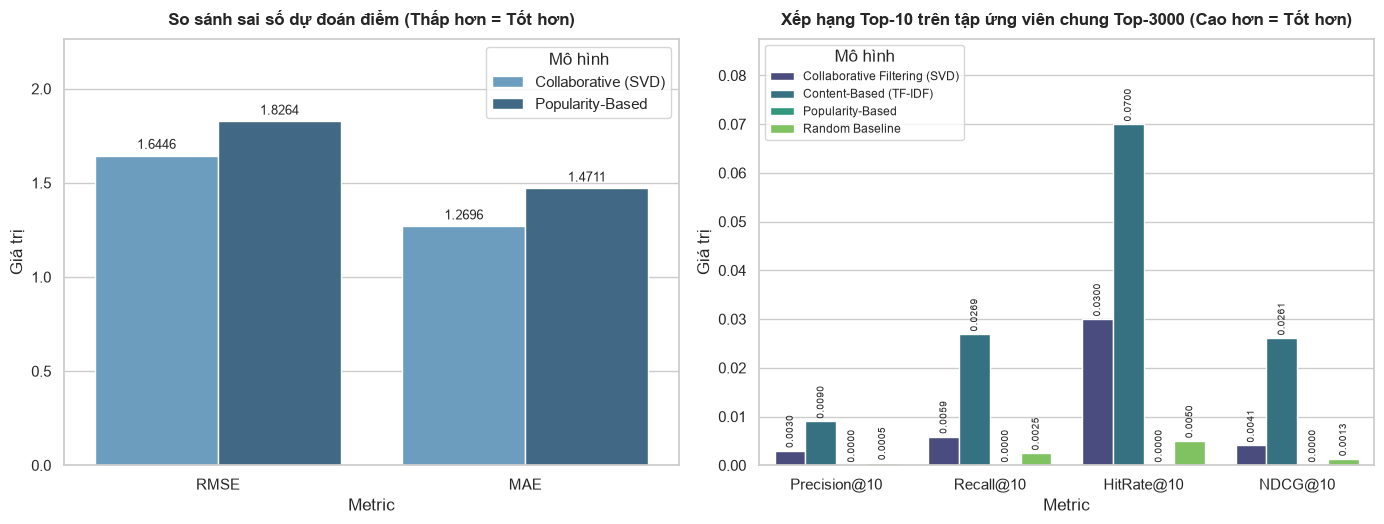

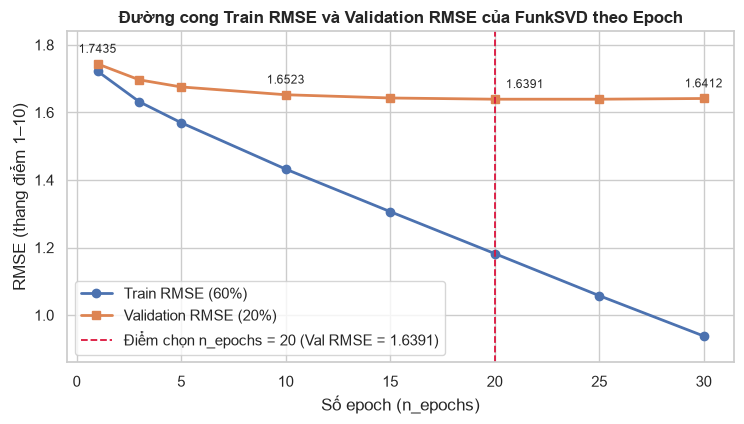

Đã lưu biểu đồ tại: ..\..\docs\images\model_evaluation_comparison.png và ..\..\docs\images\svd_epoch_curve.png


In [5]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))

# Biểu đồ trái: RMSE & MAE (SVD vs Popularity-Based Train-only)
err_df = pd.DataFrame({
    "Mô hình": ["Collaborative (SVD)", "Collaborative (SVD)", "Popularity-Based", "Popularity-Based"],
    "Metric": ["RMSE", "MAE", "RMSE", "MAE"],
    "Giá trị": [svd_rmse, svd_mae, pop_rmse, pop_mae],
})
sns.barplot(data=err_df, x="Metric", y="Giá trị", hue="Mô hình", ax=axes[0], palette="Blues_d")
axes[0].set_title("So sánh sai số dự đoán điểm (Thấp hơn = Tốt hơn)", fontweight="bold", pad=10)
axes[0].set_ylim(0, max(pop_rmse, pop_mae) * 1.24)
axes[0].legend(title="Mô hình", loc="upper right", frameon=True)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.4f", padding=3, fontsize=9)

# Biểu đồ phải: Top-10 trên cùng tập ứng viên chung Top-3000 Train
rank_melted = ranking_results_df.melt(id_vars="Mô hình", var_name="Metric", value_name="Giá trị")
sns.barplot(data=rank_melted, x="Metric", y="Giá trị", hue="Mô hình", ax=axes[1], palette="viridis")
axes[1].set_title("Xếp hạng Top-10 trên tập ứng viên chung Top-3000 (Cao hơn = Tốt hơn)", fontweight="bold", pad=10)
axes[1].set_ylim(0, ranking_results_df[["Precision@10", "Recall@10", "HitRate@10", "NDCG@10"]].max().max() * 1.25)
axes[1].legend(title="Mô hình", loc="upper left", fontsize=8.5, frameon=True)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.4f", padding=2, fontsize=7.5, rotation=90)

plt.tight_layout()
chart_path = os.path.join(IMG_DIR, "model_evaluation_comparison.png")
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

# Biểu đồ 2: Đường cong Train vs Validation RMSE theo n_epochs
fig2, ax2 = plt.subplots(figsize=(7.6, 4.4))
ax2.plot(epoch_df["n_epochs"], epoch_df["Train_RMSE"], marker="o", linewidth=2, label="Train RMSE (60%)")
ax2.plot(epoch_df["n_epochs"], epoch_df["Val_RMSE"], marker="s", linewidth=2, label="Validation RMSE (20%)")
ax2.axvline(20, color="crimson", linestyle="--", linewidth=1.3, label="Điểm chọn n_epochs = 20 (Val RMSE = 1.6391)")
for _, r in epoch_df.iterrows():
    if r["n_epochs"] in (1, 10, 20, 30):
        dx = 8 if r["n_epochs"] == 20 else 0
        ha = "left" if r["n_epochs"] == 20 else "center"
        ax2.annotate(f"{r['Val_RMSE']:.4f}", (r["n_epochs"], r["Val_RMSE"]), textcoords="offset points", xytext=(dx, 8), ha=ha, fontsize=8.5)
ax2.set_ylim(0.86, 1.84)
ax2.set_title("Đường cong Train RMSE và Validation RMSE của FunkSVD theo Epoch", fontweight="bold")
ax2.set_xlabel("Số epoch (n_epochs)")
ax2.set_ylabel("RMSE (thang điểm 1–10)")
ax2.legend(frameon=True)
plt.tight_layout()
curve_path = os.path.join(IMG_DIR, "svd_epoch_curve.png")
plt.savefig(curve_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Đã lưu biểu đồ tại: {chart_path} và {curve_path}")

### Cell 6: Kiểm chứng tính nhất quán Cold Start với `trainset` của mô hình SVD
- Xác nhận `User-ID 166596` có mặt trong `svd_model.trainset`, trong khi người dùng chỉ thuộc `Validation/Test` (`~9.872` lượt ở `test_df`) không có trong `trainset` nên tầng Backend phải định tuyến sang Popularity-Based Cold Start Fallback.

In [6]:
def in_trainset(uid: int) -> bool:
    try:
        svd_model.trainset.to_inner_uid(uid)
        return True
    except ValueError:
        return False

val_only_users = list(set(val_df["User-ID"].unique()) - train_user_set)
sample_val_only = val_only_users[0] if val_only_users else None
print("User 166596 trong SVD trainset:", in_trainset(166596))
print("User 9999999 (mới tinh) trong SVD trainset:", in_trainset(9999999))
if sample_val_only is not None:
    print(f"User {sample_val_only} (chỉ có trong Validation) trong SVD trainset:", in_trainset(sample_val_only))
print(f"Tổng số user trong SVD trainset: {svd_model.trainset.n_users:,} / {ratings_df['User-ID'].nunique():,} user toàn tập")
print(f"Số lượt Test thuộc Cold Users (chưa có trong Trainset): {(~is_warm_user).sum():,} / {len(test_df):,}")

User 166596 trong SVD trainset: True
User 9999999 (mới tinh) trong SVD trainset: False
User 98304 (chỉ có trong Validation) trong SVD trainset: False
Tổng số user trong SVD trainset: 50,636 / 68,091 user toàn tập
Số lượt Test thuộc Cold Users (chưa có trong Trainset): 9,872 / 76,769
